# PMF, CDF, Joint Distribution
### CA2 @ EPS Course

#### Instructors: Dr. Tavassolipour, Dr. Vahabie

---

### Instructions:
-  Replace the placeholders (between <font color="green">`## TODO ##`</font> and <font color="green">`## TODO ##`</font>) with the appropriate details.
- Ensure you run each cell after you've entered your solution.

---

*Full Name:* mohammadmahdi yari

*SID:* 810102532

The objective of this notebook is to understand the concepts of PMF and CDF and joint distribution.

In [1]:
import simpy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Parameters

In [2]:
num_counters = 1
arrival_rate = 5  # customers per minute
service_rate = 6  # customers per minute
simulation_time = 10000  # minutes

## Simulation

In [3]:
def simulate_queue_system():
    """
    Simulates a queue system with customers arriving at service counters, waiting for service, and being served.

    This function defines the customer behavior and the setup of the simulation environment. It initializes the simulation environment, sets up the service counters, and continuously generates customer arrivals based on specified arrival and service rates. The function runs the simulation until the specified simulation time and returns the recorded wait times, arrival times, and service times of the customers.

    Returns:
        tuple: A tuple containing three lists - wait_times, arrival_times, and service_times, which record the respective times for each customer in the simulation.
    """

    def customer(
        env: simpy.Environment,
        name: str,
        counter: simpy.Resource,
        service_time: float,
        wait_times: list,
        arrival_times: list,
        service_times: list,
    ):
        """
        Simulates a customer arriving at a service counter, waiting for service, and then being served.

        Args:
            env (simpy.Environment): The simulation environment.
            name (str): The name of the customer.
            counter (simpy.Resource): The service counter resource.
            service_time (float): The time it takes to serve the customer.
            wait_times (list): A list to record the wait times of customers.
            arrival_times (list): A list to record the arrival times of customers.
            service_times (list): A list to record the service times of customers.

        Yields:
            simpy.events.Process: The process of the customer being served.
        """
        arrival_time = env.now
        arrival_times.append(arrival_time)
        with counter.request() as req:
            yield req
            yield env.timeout(service_time)
            service_times.append(service_time)
            wait_time = env.now - arrival_time
            wait_times.append(wait_time)

    def setup(
        env: simpy.Environment,
        num_counters: int,
        arrival_rate: float,
        service_rate: float,
        wait_times: list,
        arrival_times: list,
        service_times: list,
    ):
        """
        Sets up the simulation environment with a specified number of service counters and customer arrival and service rates.

        Args:
            env (simpy.Environment): The simulation environment.
            num_counters (int): The number of service counters available.
            arrival_rate (float): The rate at which customers arrive.
            service_rate (float): The rate at which customers are served.
            wait_times (list): A list to record the wait times of customers.
            arrival_times (list): A list to record the arrival times of customers.
            service_times (list): A list to record the service times of customers.

        Yields:
            simpy.events.Timeout: The timeout event for the next customer arrival.
        """
        counter = simpy.Resource(env, num_counters)
        while True:
            yield env.timeout(np.random.exponential(1 / arrival_rate))
            service_time = np.random.exponential(1 / service_rate)
            env.process(
                customer(
                    env,
                    "Customer",
                    counter,
                    service_time,
                    wait_times,
                    arrival_times,
                    service_times,
                )
            )

    while True:
        env = simpy.Environment()
        wait_times = []
        arrival_times = []
        service_times = []
        env.process(
            setup(
                env,
                num_counters,
                arrival_rate,
                service_rate,
                wait_times,
                arrival_times,
                service_times,
            )
        )
        env.run(until=simulation_time)

        if len(wait_times) == len(arrival_times) == len(service_times):
            return wait_times, arrival_times, service_times
        
wait_times, arrival_times, service_times = simulate_queue_system()

## Plot the RVs Distributions

Text(0, 0.5, 'frequency')

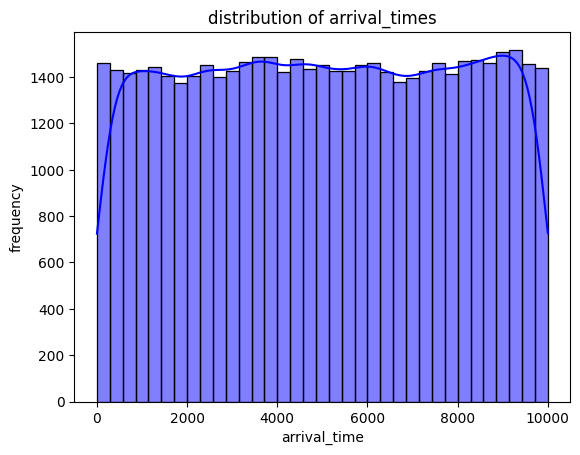

In [4]:
######################  TODO  ########################
sns.histplot(arrival_times, kde=True, bins=35, color='blue', kde_kws={'bw_adjust': 1})
plt.title('distribution of arrival_times')
plt.xlabel('arrival_time')
plt.ylabel('frequency')
######################  TODO  ########################

This graph shows the distribution of customer arrival times. Since the customer arrival process is simulated based on a Poisson distribution, we expect the arrival times to have an exponential distribution.
The KDE curve (flat line) shows the probability density function.
The value bw_adjust=1 makes the KDE curve neither too flat nor too thin, and provides a good fit to the data.
If bw_adjust is smaller, the KDE curve will show more fluctuations, and if it is larger, the curve will be flatter.

Text(0, 0.5, 'frequency')

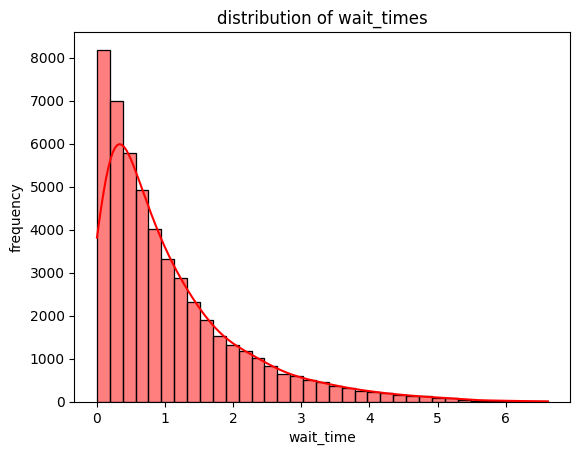

In [5]:
######################  TODO  ########################
sns.histplot(wait_times, kde=True, bins=35, color='red', kde_kws={'bw_adjust': 2})
plt.title('distribution of wait_times')
plt.xlabel('wait_time')
plt.ylabel('frequency')
######################  TODO  ########################

This graph shows the distribution of customer waiting times. The waiting time depends on the number of counters, the arrival rate, and the service rate.
The value bw_adjust=2 is used here, which makes the KDE curve smoother. This helps reduce the impact of outliers and small fluctuations.

Text(0, 0.5, 'frequency')

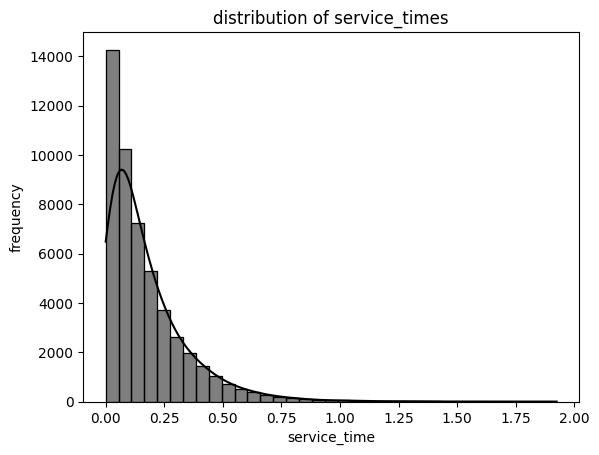

In [6]:
######################  TODO  ########################
sns.histplot(service_times, kde=True, bins=35, color='black', kde_kws={'bw_adjust': 3})
plt.title('distribution of service_times')
plt.xlabel('service_time')
plt.ylabel('frequency')
######################  TODO  ########################

This graph shows the distribution of customer service times. An exponential distribution is expected for the service times, as this process is also simulated using a Poisson process.
The value bw_adjust=3 makes the KDE curve smoother and the overall trend of the distribution better visible.

Increasing the value of bw_adjust makes the KDE curve flatter and smaller details in the data less visible. This is good for seeing the overall trend of the data.


## Plot the Joint Distributions

**Note:** Use `sns.jointplot` to plot the joint distributions

Text(37.722222222222214, 0.5, 'service_time')

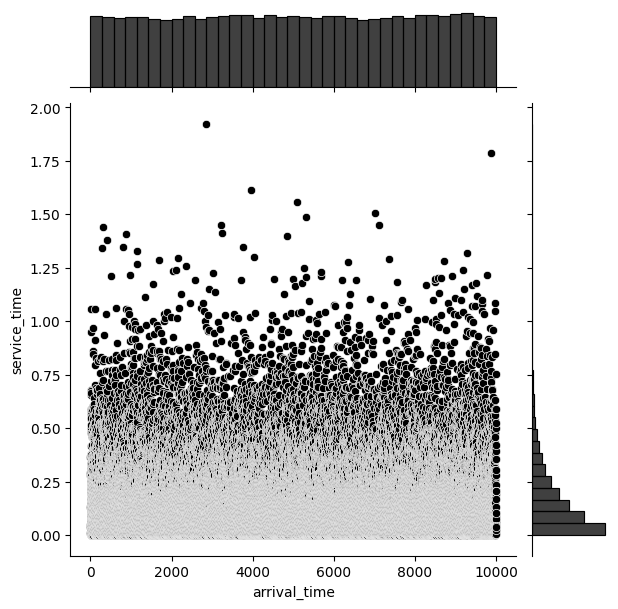

In [7]:
######################  TODO  ########################
sns.jointplot(x=arrival_times, y=service_times, kind='scatter', color='black', marginal_kws=dict(bins=35))
plt.xlabel('arrival_time')
plt.ylabel('service_time')
######################  TODO  ########################

Text(37.722222222222214, 0.5, 'wait_time')

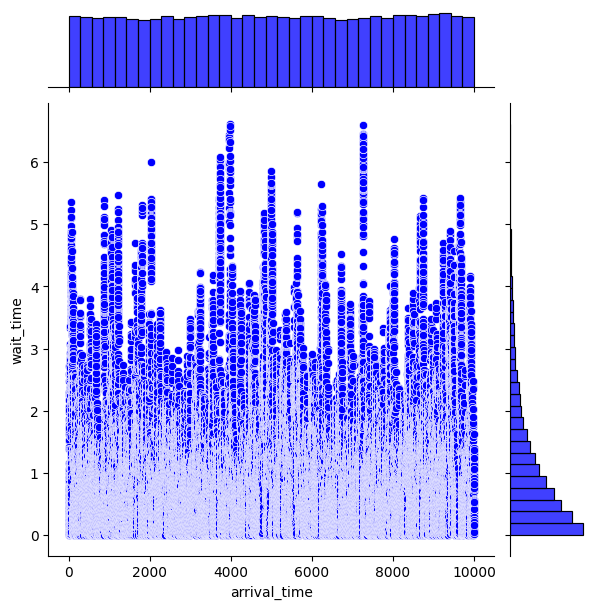

In [8]:
######################  TODO  ########################
sns.jointplot(x=arrival_times, y=wait_times, kind='scatter', color='blue', marginal_kws=dict(bins=35))
plt.xlabel('arrival_time')
plt.ylabel('wait_time')
######################  TODO  ########################

## Analysis of Joint Distributions

If the points on the scatterplot are close to a line (either ascending or descending), it indicates a strong correlation between the two variables.
If the points are scattered and randomly distributed, it indicates a weak correlation coefficient or no correlation.
And it is clear from the graph that they are distributed independently, so the correlation coefficient is close to zero.

## Scatter Plot and Correlation

0.024101015787159407


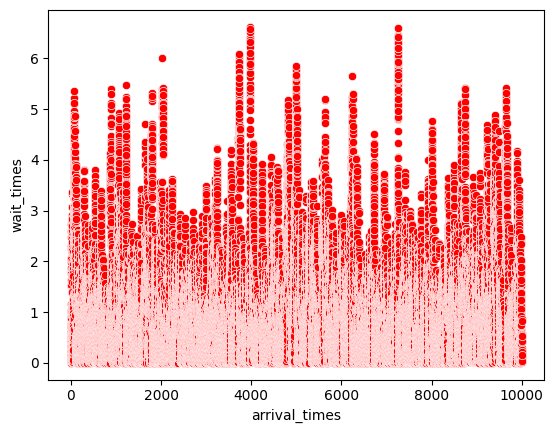

In [9]:
######################  TODO  ########################
sns.scatterplot(x=arrival_times, y=wait_times, color='red')
plt.xlabel('arrival_times')
plt.ylabel('wait_times')
ans = np.corrcoef(arrival_times, wait_times)[0, 1]
print(ans)
######################  TODO  ########################

## Calculating `total_times`

[0.2607619974477752, 0.5856155253825693, 0.1409269001686566, 0.07819771517704976, 0.732186119897325, 0.7829152754712689, 0.48334774416610105, 0.37586439599061483, 0.3163481236160675, 0.19644209227078094, 0.05756553053414842, 0.8364840515434269, 0.4571674870935343, 0.5416298980174483, 0.4097567897591411, 0.4458343581081885, 0.5540044610749919, 1.0276993202111042, 1.4008054977018536, 0.562707100222011, 0.8376539907091083, 0.47887619727312547, 0.46358846355815075, 0.6937356534235415, 0.24261585121212886, 0.7111115044231985, 0.4342876790035207, 0.20921981580930088, 0.055845442128589565, 0.004706968233078308, 0.07137502035446996, 0.25060597797303263, 0.25642129311787953, 0.11551708172743223, 0.24311713699065007, 0.2691118690607648, 0.4160482965466517, 1.5305333371486478, 0.8390425925199302, 1.174801876308545, 1.2323525178749848, 0.8011049338656293, 0.8510631355293121, 0.2525521031725314, 0.24310385095260162, 0.20724556425974722, 0.4704282230459826, 0.1414920485931439, 0.19348726724448206, 1

Text(0, 0.5, 'Frequency')

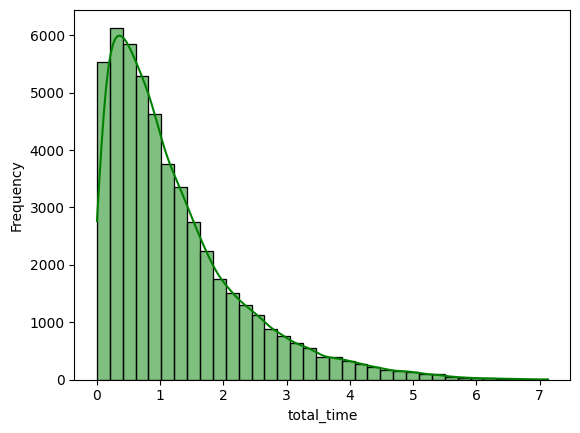

In [10]:
######################  TODO  ########################
total_times = []
for i in range(len(wait_times)):
    total_time = service_times[i] + wait_times[i]
    total_times.append(total_time)
print(total_times)
sns.histplot(total_times, kde=True, bins=35, color='green', kde_kws={'bw_adjust': 1})
plt.xlabel('total_time')
plt.ylabel('Frequency')
######################  TODO  ########################

Both of our time series have exponential distributions and are independent of each other, and we know that the sum of the two exponential distributions is equal to the gamma distribution, and the graph is also a gamma distribution, if f(x) = 𝜆𝑒^(-𝜆x) , f(y) = 𝜆𝑒^(-𝜆y) 
and Z = X + Y we have f(z) = 𝜆^2ze^(-𝜆z)

## Conditional Wait Times

[0.2607619974477752, 0.5856155253825693, 0.1409269001686566, 0.07819771517704976, 0.732186119897325, 0.7829152754712689, 0.48334774416610105, 0.37586439599061483, 0.3163481236160675, 0.19644209227078094, 0.05756553053414842, 0.8364840515434269, 0.4571674870935343, 0.5416298980174483, 0.4097567897591411, 0.4458343581081885, 0.5540044610749919, 1.0276993202111042, 1.4008054977018536, 0.562707100222011, 0.8376539907091083, 0.47887619727312547, 0.46358846355815075, 0.6937356534235415, 0.24261585121212886, 0.7111115044231985, 0.4342876790035207, 0.20921981580930088, 0.055845442128589565, 0.004706968233078308, 0.07137502035446996, 0.25060597797303263, 0.25642129311787953, 0.11551708172743223, 0.24311713699065007, 0.2691118690607648, 0.4160482965466517, 1.5305333371486478, 0.8390425925199302, 1.174801876308545, 1.2323525178749848, 0.8011049338656293, 0.8510631355293121, 0.2525521031725314, 0.24310385095260162, 0.20724556425974722, 0.4704282230459826, 0.1414920485931439, 0.19348726724448206, 1

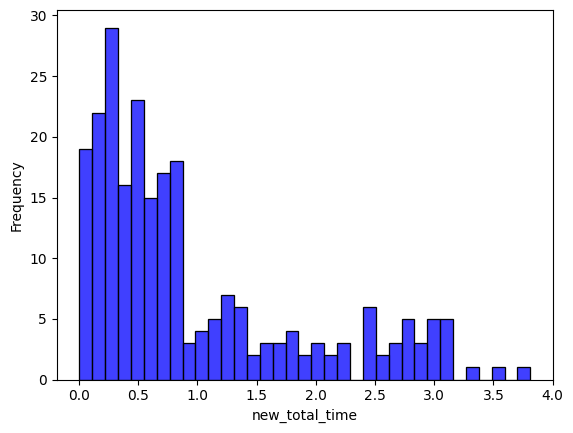

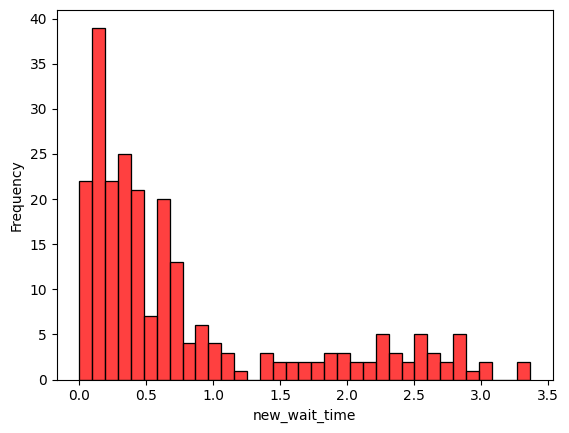

In [17]:
######################  TODO  ########################
new_total_times = []
new_wait_times = []
for i in range(len(arrival_times)):
    if arrival_times[i] < 50:
        new_total_times.append(wait_times[i] + service_times[i])
        new_wait_times.append(wait_times[i])
print(new_total_times)
print(new_wait_times)
sns.histplot(new_total_times, bins=35, color='blue', kde_kws={'bw_adjust': 1})
plt.xlabel('new_total_time')
plt.ylabel('Frequency')
plt.show()

sns.histplot(new_wait_times, bins=35, color='red', kde_kws={'bw_adjust': 1})
plt.xlabel('new_wait_time')
plt.ylabel('Frequency')
plt.show()

######################  TODO  ########################